# AMS 595/DCS 525 &nbsp;|&nbsp; Homework 3 (Python Project 1)
## Gradient Descent, Linear and Logistic Regression, and Image Classification

<div style="border:2px solid #8b0000; padding:10px; background-color:#fff8dc;">
<b style="color:#8b0000;">Important Note</b><br>
<b>You must write your code independently.</b> Do not copy code from any source. To receive full credit, your code must be well documented with comments.
</div>

## Introduction

In this project you will implement, in plain `numpy`, several of the optimization and learning algorithms covered in class. You will:

* derive and implement gradient descent for a one-dimensional smooth function and study how the step size affects convergence;
* fit a linear regression model with two features using the normal equation and visualize the fitted plane;
* tune and document a logistic regression model trained by gradient descent;
* build a logistic regression image classifier (cat vs. non-cat) from scratch and analyze its failures.

Several parts depend on your Stony Brook ID (SBU ID). Wherever this is the case, **state the digit(s) you used in a markdown cell** so the grader can reproduce your numbers.

## Project Requirements

### Due Date

⏱ **Sunday, 11:59 PM EST, October 18th, 2026** ⏱

### What to Submit

All materials are submitted through **Brightspace**. You will submit **three Jupyter notebooks**:

| File | Contents |
|---|---|
| `LastName_FirstName_HW3.ipynb` | This notebook, with Questions 1 to 4 completed |
| `LastName_FirstName_HW3_Q5a.ipynb` | Question 5, Tasks 5.1 and 5.2 (original train/test split) |
| `LastName_FirstName_HW3_Q5b.ipynb` | Question 5, Task 5.3 (modified train/test split) |

Package them for upload as follows:

1. **Source code.** Compress the three `.ipynb` files into a single ZIP archive named `LastName_FirstName_HW3.zip`.
2. **Output PDF.** Export each notebook to PDF (*File → Save and Export Notebook As → PDF*, or print to PDF from the browser), merge them into a single file named `LastName_FirstName_HW3.pdf`, and upload it alongside the ZIP.
3. **GitHub (optional, highly recommended).** Push the notebooks to a GitHub repository and paste the link in the Brightspace submission comment.

### Notebook Rules

* **Run every cell before submitting** (*Kernel → Restart & Run All*). All printed values and figures must be visible in the submitted notebooks. Results that are not visible in the output will not receive credit.
* Use only `numpy`, `scipy`, and `matplotlib` for computation and plotting. The only exception is `h5py`, which you may use in Question 5 solely to read the `.h5` data files.
* Keep the question structure of this notebook. Put your code in the provided cells (add more cells as needed) and put written answers in markdown cells directly below the corresponding code.
* The comments inside the starter cells are guidance only. You may take a different approach as long as it satisfies the stated requirements.

### Academic Integrity and Late Work

All submissions are automatically checked for plagiarism. Your work must be your own, and any outside material must be properly cited. Late submissions incur a penalty as outlined in the course syllabus, unless an extension has been approved in advance.

## Point Summary

This project is worth **150 points** in total.

| Question | Topic | Points |
|---|---|---|
| Q1 | Presentation, documentation, and submission | 10 |
| Q2 | Gradient descent on $f(x)=\sqrt{x^2+5}$ | 60 |
| Q3 | Linear regression with two features (normal equation) | 30 |
| Q4 | Logistic regression: tuning and documentation | 20 |
| Q5 | Image binary classification (cat vs. non-cat) | 30 |
| | **Total** | **150** |

The detailed rubric for each question is listed inside the question and summarized again in the Grading Rubric at the end of this notebook.

---
## Q1. Presentation, Documentation, and Submission (10 pts)

These points are awarded across all three notebooks.

| Item | Points |
|---|---|
| Code is commented clearly enough that a classmate could follow each step | 3 |
| Every figure has a title, labeled axes (with units or quantity names), and a legend whenever more than one curve is shown | 3 |
| Code is split into logical cells, each preceded by a short markdown explanation; mathematical reasoning is written in LaTeX ($\LaTeX$) | 2 |
| Files follow the naming convention, all cells are executed with outputs visible, and both the ZIP and the merged PDF are submitted | 2 |
~~~~#%% md
---
## Q2. Implementing the Gradient Descent Algorithm (60 pts)

Consider the function
$$
f(x) = \sqrt{x^2 + 5}, \qquad x \in \mathbb{R}.
$$

**Fact:** $f$ is $L$-smooth, meaning its derivative $f'$ is Lipschitz continuous with constant $L$: $|f'(x) - f'(y)| \le L\,|x - y|$ for all $x, y \in \mathbb{R}$.

Gradient descent (GD) with step size $\alpha > 0$ starts from an initial guess $x_0$ and iterates
$$
x_{k+1} = x_k - \alpha\, f'(x_k), \qquad k = 0, 1, \dots, T-1,
$$
where $x_k$ is the iterate after $k$ steps and $T$ is the total number of iterations.

**Your initial guess.** Let $d$ be the last digit of your SBU ID. Use
$$
x_0 = \frac{d}{5} + 1 .
$$
For example, if your ID ends in 9, then $x_0 = 9/5 + 1 = 2.8$. If your ID ends in 0, then $x_0 = 1.0$.

### Tasks

**2.0 Analytic work (10 pts).** In a markdown cell, using LaTeX:
* (5 pts) derive $f'(x)$ and find the minimizer $x^\ast$ and the minimum value $f(x^\ast)$, with a short justification of why it is the global minimum;
* (5 pts) compute $f''(x)$ and show that $L = \max_x |f''(x)| = 1/\sqrt{5}$. Use this to state the step-size threshold $2/L$ (numerical value to 3 decimal places).

**2.1 Plot $f$ (5 pts).** Plot $f(x)$ on the interval $[-5, 5]$ using at least 200 points. Mark the minimizer $x^\ast$ on the plot.

**2.2 Implement GD (15 pts).** Write a function
```python
def gradient_descent(x0, step_size, num_iterations):
    ...
    return xs   # numpy array of length num_iterations + 1: [x_0, x_1, ..., x_T]
```
The function must use your analytic $f'(x)$ from 2.0 (not a numerical derivative), and must return the whole trajectory including $x_0$.

**2.3 Run GD and report $x_T$ (5 pts).** Run your function with $\alpha = 1$ and $T = 50$. Print $x_0$, $x_T$, and $f(x_T)$, each to 6 decimal places.

**2.4 Convergence plot (10 pts).** Plot $f(x_k)$ versus the iteration number $k$ for $k = 0, 1, \dots, 50$ (the run from 2.3). Add a horizontal dashed line at the minimum value $f(x^\ast)$.

**2.5 Effect of step size (15 pts).**
* (10 pts) For each step size $\alpha \in \{5, 3, 1, 0.5\}$, run GD from the same $x_0$ for $T = 50$ iterations. On **one** figure, plot the per-step decrease
$$
\Delta_k = f(x_{k-1}) - f(x_k), \qquad k = 1, 2, \dots, 50,
$$
versus $k$, with one curve per step size and a legend. Use a linear $y$-axis (since $\Delta_k$ may be negative) and draw a horizontal reference line at $\Delta_k = 0$.
* (5 pts) In a markdown cell, answer: for which step sizes is $\Delta_k \ge 0$ for every $k$ (so that $f(x_k)$ never increases)? Once GD has converged, $\Delta_k$ becomes extremely small, so treat any $|\Delta_k| < 10^{-12}$ as zero (floating-point roundoff). For each step size, print the smallest $\Delta_k$ and the number of steps with $\Delta_k < -10^{-12}$ to support your answer. Explain the behavior you observe using the threshold $2/L$ from 2.0. Is $\alpha < 2/L$ a sufficient condition for monotone decrease? Is it necessary? (Hint: the answer for $\alpha = 5$ depends on $x_0$. Try at least one other initial guess in addition to yours before you answer.)
~~~~#%% md
Here are some sample output graphs for reference. Your graphs do not need to look exactly like these. Some parameters and plot details were changed on purpose so that the figures do not reveal the solution.

![Sample: plot of f(x)](attachment:o1.png)
![Sample: f(x_k) vs. k](attachment:o2.png)
![Sample: step size comparison](attachment:o3.png)

### 2.0 Analytic work (write your answer here)

*Your derivation of $f'(x)$, $x^\ast$, $f(x^\ast)$, $f''(x)$, $L$, and $2/L$.*

### Part 1 Derivation of $f'(x)$

   $ f(x) = \sqrt{x^2 + 5} x \in \mathbb{R} $

$ \newline $
  $  Let \: u = x^2 + 5 $

  $  \newline $
  $  f(u) = \sqrt{u} $

  $\; du = 2x $

  $  \newline $
  $  f'(u) = \frac{1}{2 \sqrt{u}} du $

  $ \newline $
  $ f'(x) = \frac{x}{\sqrt{x^2 + 5}} $

$ Extrema \ for \ f(x) \ is \ when  \ f'(x) = 0 $
$ \newline $
$ for \ f(x) \ f'(x) = 0 \ when \  \frac{x}{\sqrt{x^2 + 5}} = 0  \ which  \ is \ 0 \ only \ when \ x = 0 \  $
$ \newline $
$ we \ now \ know \ that \ x = 0 \ is \ an \ extrema \ point $
$ \newline $
$ notice \ f'(x) \ for \ x < 0 \ is  \ postive $
$ \newline $
$ because \ for  \ x<0: \ x^2 >0 \ and \ thus \ x^2 + 5 >0 $
$\newline $
$ similarly \ for \ f'(x) \ for \ x >0  \ is \ postive \ $
$\newline$
$ because \ for \ x>0: x^2 + 5>0 $
$ \newline $
$ This \ tells \ us \ for \ all \ points \ but \ x=0 \ f(x) \ is \ increasing \ $
$\newline$
$thus \ f(x =0) \ is \ the \ minimum \ value \  and \ the \ global \ minimum \ value \ x =0 \ is \ the \ minimizer $
$\newline$
$notice \ f(0) \ = \sqrt{5} \ and \ thus \ \sqrt{5} \ is \ the \ minimum $

### 2.0 Part 2: Smoothness constant


From Part 1, $f'(x)=\frac{x}{\sqrt{x^2+5}}=x(x^2+5)^{-1/2}$.

Differentiate again:

$$
\begin{aligned}
f''(x)
&= (x^2+5)^{-1/2}
+ x\left(-\frac{1}{2}\right)(x^2+5)^{-3/2}(2x) \\
&= \frac{1}{\sqrt{x^2+5}}
- \frac{x^2}{(x^2+5)^{3/2}} \\
&= \frac{x^2+5-x^2}{(x^2+5)^{3/2}} \\
&= \frac{5}{(x^2+5)^{3/2}}.
\end{aligned}
$$

Since $f''(x) > 0$ for every $x$,

$$
|f''(x)|=\frac{5}{(x^2+5)^{3/2}}.
$$

This expression is largest when $x=0$, because the denominator is smallest there. Therefore,

$$
L=\max_x |f''(x)|
=|f''(0)|
=\frac{5}{5^{3/2}}
=\frac{1}{\sqrt{5}}.
$$

The step-size threshold is:

$$
\frac{2}{L}
=\frac{2}{1/\sqrt{5}}
=2\sqrt{5}
\approx 4.472.
$$

Therefore, the usual gradient descent condition is:

$$
0 < \alpha < 2\sqrt{5} \approx 4.472.
$$

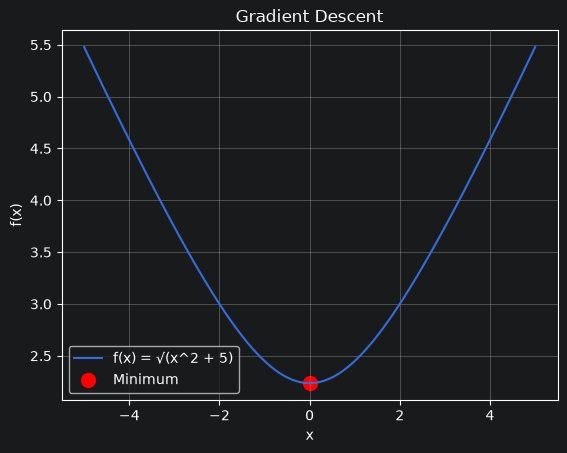

In [75]:
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt
import numpy as np

# State the last digit d of your SBU ID and compute the initial guess x_0 = d/5 + 1.
d = 6.0   # <-- replace with the last digit of your SBU ID
x0 =  d/5 + 1


# 2.1 Define the function f(x).
def f(x):
    return (x**2 + 5)**(1/2)

# 2.1 Plot f(x) on [-5, 5] (np.linspace might be helpful) and mark the minimizer x*.

#This defines the input space for the function f(x)
x = np.linspace(-5,5,200)

#plots 200 pts of f(x) and the min point which is f(0) using matplotlib
plt.plot(x,f(x), label="f(x) = \N{SQUARE ROOT}(x^2 + 5)")

plt.scatter(0,f(0), color="red", s=100, label="Minimum" )
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title("Gradient Descent")


plt.legend()
plt.grid()
plt.show()

This cell below creates the gradient descent function, which is finds the minimum of a function. $$
x_{k+1}
=
x_k
-
\alpha \frac{x_k}{\sqrt{x_k^2+5}}.
$$

x0:2.200000, x_T:0.000000, f(x_T):2.236068


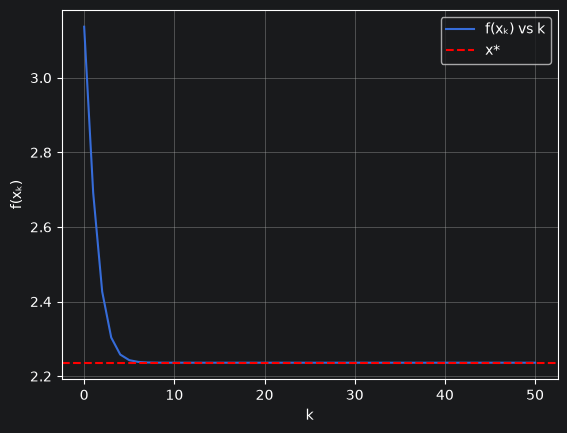

In [76]:
# 2.2 Define the derivative f'(x) (use your analytic result from 2.0).
import numpy as np
import matplotlib.pyplot as plt
# State the last digit d of your SBU ID and compute the initial guess x_0 = d/5 + 1.
d = 6.0   # <-- replace with the last digit of your SBU ID
x0 =  d/5 + 1


#need this for f(x_T)
def f(x):
    return (x**2 + 5)**(1/2)


def f_1stder(x):
    return (x) / (x**2 + 5)**(1/2)


# 2.2 Write gradient_descent(x0, step_size, num_iterations) that returns the
#     array [x_0, x_1, ..., x_T] of length num_iterations + 1.
def gradient_descent(x_0,step_size,num_iterations):

    #this is the return array, it is first an array of zeros to make this run faster
    path_array = np.zeros(num_iterations + 1)

    #This is the starting point for the algrothium
    path_array[0] = x_0

    for i in range(num_iterations):
        #returns a new step in direction of greastest descent
        x_0 = x_0 - step_size * f_1stder(x_0)
        #stores the step in the path array
        path_array[i + 1] = x_0

    return path_array

# 2.3 Run GD with step_size = 1 and num_iterations = 50; print x_0, x_T, f(x_T) to 6 decimals.

#our output text will reference this call of the function
path_array = gradient_descent(x0,1,50)
x_T = path_array[50]

print(f"x0:{x0:.6f}, x_T:{x_T:.6f}, f(x_T):{f(x_T):.6f}")

# 2.4 Plot f(x_k) vs. k, with a dashed horizontal line at f(x*).

# numbers 0 to 50 by 1
k = np.linspace(0,50,51)
plt.plot(k,f(path_array), label = "f(x\u2096) vs k")

#adds the dashed line at f(x*)
plt.axhline(y=f(path_array[50]), color="red", linestyle="--",label = "x*")

plt.xlabel("k")
plt.ylabel("f(x\u2096)")

plt.legend()
plt.grid()
plt.show()


For each $\alpha \in \{5,3,1,0.5\}$, the code uses gradient descent,
$x_{k+1}=x_k-\alpha\frac{x_k}{\sqrt{x_k^2+5}}$, to generate
$x_0,\ldots,x_{50}$ and calculates
$\Delta_k=f(x_{k-1})-f(x_k)$ for $k=1,\ldots,50$.

The graph shows whether $f(x_k)$ decreases ($\Delta_k>0$) or increases
($\Delta_k<0$) at each step, while the additional $\alpha=5,\ x_0=1$
test shows how the starting point can change the behavior.

alpha = 5: smallest Delta_k = 0.000000000001, steps with Delta_k < -1e-12 = 0
alpha = 3: smallest Delta_k = 0.000000000000, steps with Delta_k < -1e-12 = 0
alpha = 1: smallest Delta_k = 0.000000000000, steps with Delta_k < -1e-12 = 0
alpha = 0.5: smallest Delta_k = 0.000000000013, steps with Delta_k < -1e-12 = 0


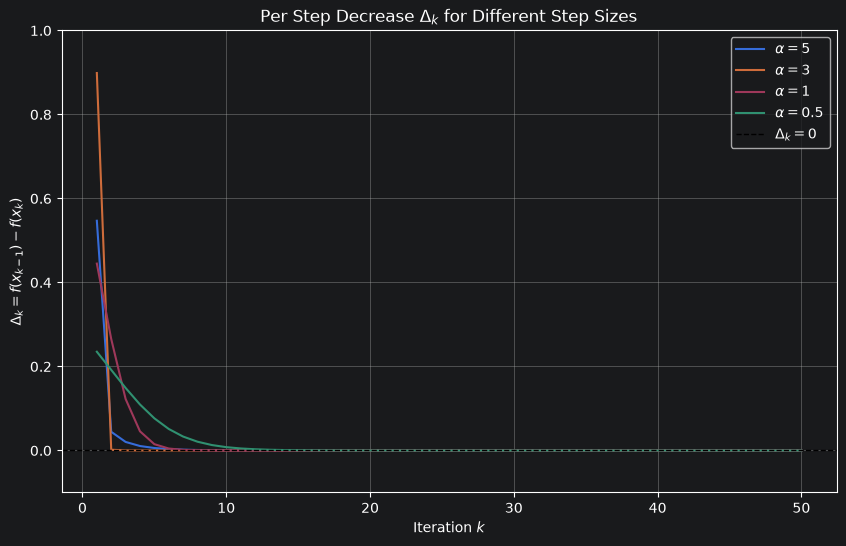

Other initial guess: x0 = 1.0
Smallest Delta_k: -0.017124082287
Steps with Delta_k < -1e-12: 47


In [77]:
# 2.5 List of step sizes to compare.
#  same starting point for every run.
x0 = 6 / 5 + 1
T = 50

step_sizes = [5, 3, 1, 0.5]


# Run GD for each step size from the same x_0 and store the trajectories.

# k = 1 through 50, since Delta_k compares x_(k-1) with x_k.
k_values = np.arange(1, T + 1)

# Store delta values for later .
all_deltas = {}

plt.figure(figsize=(10, 6))

for alpha in step_sizes:

    # Run gradient descent and obtain x_0 through x_50.
    path = gradient_descent(x0, alpha, T)

    # Calculate f(x_0), f(x_1), ..., f(x_50).
    function_values = np.array([f(x) for x in path])

    # Delta_k = f(x_(k-1)) - f(x_k), for k = 1 through 50.
    deltas = function_values[:-1] - function_values[1:]

    # Save the deltas for this step size.
    all_deltas[alpha] = deltas

    # Plot one curve for this alpha.
    plt.plot(k_values, deltas, label=rf"$\alpha={alpha}$")

    # Print the  numerical evidence.
    smallest_delta = np.min(deltas)
    negative_steps = np.sum(deltas < -1e-12)

    print(
        f"alpha = {alpha}: "
        f"smallest Delta_k = {smallest_delta:.12f}, "
        f"steps with Delta_k < -1e-12 = {negative_steps}"
    )

# Add the required zero reference line.
plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1,
    label=r"$\Delta_k=0$"
)

plt.xlabel(r"Iteration $k$")
plt.ylabel(r"$\Delta_k=f(x_{k-1})-f(x_k)$")
plt.title(r"Per Step Decrease $\Delta_k$ for Different Step Sizes")
plt.legend()
plt.grid()
plt.ylim(-0.1, 1.0)
plt.show()

# Test alpha = 5 from another initial guess.
other_x0 = 1.0

other_path = gradient_descent(other_x0, 5, T)
other_f_values = np.array([f(x) for x in other_path])
other_deltas = other_f_values[:-1] - other_f_values[1:]

print(f"Other initial guess: x0 = {other_x0}")
print(f"Smallest Delta_k: {np.min(other_deltas):.12f}")
print(f"Steps with Delta_k < -1e-12: {np.sum(other_deltas < -1e-12)}")

# Plot all Delta_k curves on a single figure with a legend and a reference line at 0.

### 2.5 Discussion (write your answer here)

*Which step sizes give $\Delta_k > 0$ for all $k$? Relate your observations to $2/L$, and comment on sufficiency and necessity.*

For my assigned initial guess $x_0=2.2$, all four step sizes
$\alpha \in \{5, 3, 1, 0.5\}$ had zero steps with
$\Delta_k < -10^{-12}$. Thus, within the required floating point
tolerance, $f(x_k)$ never increased for any of these step sizes.
Since $L=1/\sqrt{5}$, the threshold is $2/L=2\sqrt{5}\approx 4.472$.
Therefore, $\alpha=0.5$, $\alpha=1$, and $\alpha=3$ are below the
threshold, so monotonic decrease is guaranteed by the sufficient
condition $\alpha < 2/L$. Although $\alpha=5$ is above the threshold,
it still had no negative $\Delta_k$ values from $x_0=2.2$; however,
when I tried $\alpha=5$ from $x_0=1.0$, the smallest
$\Delta_k$ was approximately $-0.017124$ and 47 steps had
$\Delta_k < -10^{-12}$. Therefore, $\alpha < 2/L$ is sufficient for
monotone decrease, but it is not necessary for a particular initial
guess.

---
## Q3. Linear Regression with Two Features (30 pts)

In class we fit a linear regression model with one-dimensional features. The cell below generates synthetic data with **two-dimensional** features $\mathbf{x} = (x_1, x_2)$ and a scalar response $y$ from the model
$$
y = 4 + 4x_1 + 0.5x_2 + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, 1),
$$
where $\varepsilon$ is standard normal noise. The true intercept is $\theta_0 = 4$ and the true coefficients are $\theta_1 = 4$ and $\theta_2 = 0.5$.

**Random seed.** Change the random seed to the **last two digits** of your SBU ID. For example, if your ID is 123456987, use `np.random.seed(87)`. If the last two digits are `05`, use `np.random.seed(5)`.

Let $m = 100$ be the number of samples, $X_b \in \mathbb{R}^{m \times 3}$ be the design matrix (a column of ones followed by the two feature columns), and $\mathbf{y} \in \mathbb{R}^{m}$ be the response vector. The normal equation gives the least-squares parameters
$$
\hat{\boldsymbol\theta} = (X_b^\top X_b)^{-1} X_b^\top \mathbf{y}, \qquad \hat{\boldsymbol\theta} = (\hat\theta_0, \hat\theta_1, \hat\theta_2)^\top .
$$

### Tasks

**3.1 Design matrix (5 pts).** Set your seed, generate the data, and build $X_b$ by prepending a column of ones to `X`. Print the shape of $X_b$.

**3.2 Normal equation (10 pts).** Compute $\hat{\boldsymbol\theta}$ with the normal equation using `numpy` linear algebra. Prefer `np.linalg.solve(Xb.T @ Xb, Xb.T @ y)` over forming the inverse explicitly. Do **not** use `np.linalg.lstsq`, `np.polyfit`, or any library regression routine for this step (you may use one afterwards to check your answer).

**3.3 Report (5 pts).** Print the intercept $\hat\theta_0$ and coefficients $\hat\theta_1, \hat\theta_2$ to 4 decimal places, next to the true values $(4, 4, 0.5)$. Also print the mean squared error (MSE) $\frac{1}{m}\sum_{i=1}^{m}(y_i - \hat y_i)^2$ of your fit on the data, where $\hat y_i$ is the fitted value for sample $i$. In one or two sentences, explain why $\hat{\boldsymbol\theta}$ is not exactly equal to the true parameters.

**3.4 3D plot (10 pts).** On one 3D figure, show the data points as a scatter plot and the fitted regression plane $\hat y = \hat\theta_0 + \hat\theta_1 x_1 + \hat\theta_2 x_2$ as a semi-transparent surface over the range of the data. Label the axes $x_1$, $x_2$, and $y$. `numpy.linspace`, `numpy.meshgrid`, and the [Surface Plot](https://matplotlib.org/stable/gallery/mplot3d/surface3d.html) example may help.

Here is a sample output graph for reference. Yours does not need to look exactly like it.

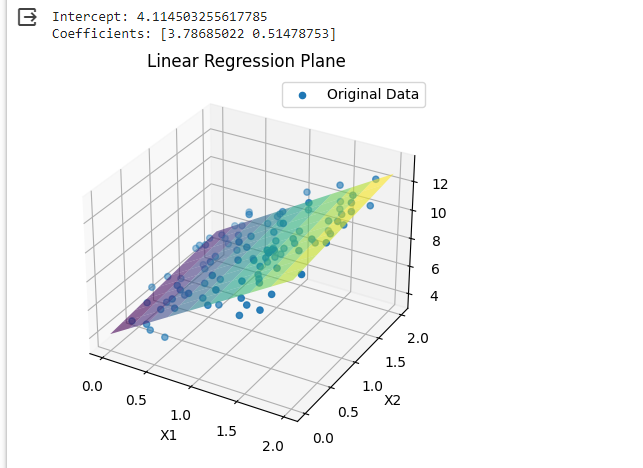

The code generates noisy data from $y=4+4x_1+0.5x_2+\varepsilon$ and
fits the linear regression parameters using the normal equation
$\hat{\theta}=(X_b^T X_b)^{-1}X_b^T y$.

It then calculates the mean squared error
$\mathrm{MSE}=\frac{1}{100}\sum_{i=1}^{100}(y_i-\hat{y}_i)^2$ and
plots the fitted plane
$\hat{y}=\hat{\theta}_0+\hat{\theta}_1x_1+\hat{\theta}_2x_2$ with the
original data points.

(100, 3)
Approximation| Intercept ^θ̂₀: 4.5327, Coefficients ^θ̂₁: 3.7368, ^θ̂₁: 0.3004
True values| Intercept θ₀: 4.0000, Coefficients θ̂₁: 4.0000, θ̂₁: 0.5000
MSE: 0.8665


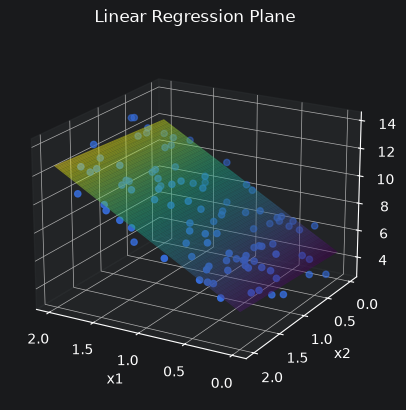

In [78]:
import numpy as np
import matplotlib.pyplot as plt

#d = 06
# Generate synthetic data
np.random.seed(6)   # <-- change the seed to the last two digits of your SBU ID
X = 2 * np.random.rand(100, 2)                                  # 100 random 2D data points
y = 4 + 4 * X[:, 0] + 0.5 * X[:, 1] + np.random.randn(100)      # y values with noise

# 3.1 Add a column of ones to X for the intercept term and print the shape of Xb.
intercept_X_Terms = np.ones((100,1))

#Creates a matrix of a col of ones adjointed to the matrix X to create Xb
matrix_Xb = np.hstack((intercept_X_Terms, X))

#prints shape of Xb
print(matrix_Xb.shape)

# 3.2 Find theta using the normal equation.


theta = np.linalg.solve(matrix_Xb.T @ matrix_Xb, matrix_Xb.T @ y)




# 3.3 Print the intercept and coefficients (4 decimals) next to the true values, and the MSE.

print(f"Approximation| Intercept ^θ̂₀: {theta[0]:.4f}, Coefficients ^\u03B8\u0302\u2081: {theta[1]:.4f}, ^\u03B8\u0302\u2081: {theta[2]:.4f}")
print(f"True values| Intercept \u03B8\u2080: {4:.4f}, Coefficients \u03B8\u0302\u2081: {4:.4f}, \u03B8\u0302\u2081: {0.5:.4f}")

#MSE
# for (yi - ^yi) we will compare tue array y with the array I make using the values for theta
#Notice theta[0] = intercept and theta 1 and 2 are the coefficents
y_hat = theta[0] + theta[1] * X[:,0] + theta[2] * X[:,1]

#MSE m = 100 because there are 100 pts in X
m =100
#creates an array with m zeros
mse_sum = np.zeros(m)
#This is creates an array with 100 entries where each entry is (yi - y^i)^2
for k in range(m):
    mse_sum[k] = (y[k]-y_hat[k])**2

#sums up the array and divdies it by the amount of entries
mse = (1/m) * np.sum(mse_sum)

print(f"MSE: {mse:.4f}")
## 3.4 Plot the generated data and the regression plane in one 3D figure.
#axis for graph
x1 = np.linspace(0,2,100)
x2 = np.linspace(0,2,100)
X1,X2 = np.meshgrid(x1,x2)

#fucntion of regression plane so it can be called when graphed
def y_hat_function(x1,x2):
    y = theta[0] + theta[1] * x1 + theta[2] * x2
    return y


fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

#plots plane, alpha = 0.5 makes it 1/2 clear
Z = y_hat_function(X1,X2)
ax.plot_surface(X1, X2, Z, cmap="viridis",alpha = 0.5)

#orignal data points
ax.scatter(X[:,0],X[:,1], y,label="Orginal Data" )


ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Linear Regression Plane")
#changes camera angle
ax.view_init(elev=20, azim=120)
plt.show()

### 3.3 Discussion (write your answer here)

*Why does $\hat{\boldsymbol\theta}$ differ from $(4, 4, 0.5)$?*

$\hat{\theta}$ differs from (4,4,0.5) because least square regression uses the mean, which can cause inaccuracies if the data is skewed (the data is almost never perfectly symmerical due to the random noise). Another factor is the random noise itself which by definition interfers with the data being collected: a little error on each point accumulates and leds to a larger error at the end, as the number of points increases, there will tend to be a better appromation

---
## Q4. Logistic Regression: Tuning and Documentation (20 pts)

Below is the logistic regression code we discussed in class. The values of `learning_rate` and `num_epochs` have been changed, and all comments have been removed.

The model predicts the probability $\hat y = \sigma(\mathbf{w}^\top \mathbf{x} + b)$, where $\mathbf{x} \in \mathbb{R}^2$ is a feature vector, $\mathbf{w} \in \mathbb{R}^2$ is the weight vector, $b \in \mathbb{R}$ is the bias, and $\sigma(z) = 1/(1+e^{-z})$ is the sigmoid function. Training minimizes the average binary cross-entropy loss over the $m = 80$ training samples,
$$
J(\mathbf{w}, b) = -\frac{1}{m}\sum_{i=1}^{m}\Big[\,y_i \log \hat y_i + (1 - y_i)\log(1 - \hat y_i)\Big],
$$
where $y_i \in \{0, 1\}$ is the label of sample $i$. Let $\boldsymbol\theta = (\mathbf{w}, b)$ denote all parameters and $\boldsymbol\theta^\ast$ the minimizer of $J$.

**Do not change** the data generation (including `np.random.seed(595)`) or the train/test split.

### Tasks

**4.1 Tune the learning rate and number of epochs (8 pts).** Choose `learning_rate` and `num_epochs` so that the final parameters $\boldsymbol\theta$ closely approximate $\boldsymbol\theta^\ast$. Use the following convergence criterion: the training loss $J$ changes by less than $10^{-6}$ over the last 100 epochs. Note that accuracy alone is **not** a good indicator here, because the accuracy can stop changing long before $\boldsymbol\theta$ converges.
* Record $J$ at every epoch.
* Print your chosen `learning_rate` and `num_epochs`, the final $\mathbf{w}$ and $b$ (4 decimals), the final training loss $J$ (6 decimals), and the training and test accuracies.
* In a markdown cell, explain in 3 to 5 sentences how you chose these values (for example, what happens when the learning rate is too small or too large).

**4.2 Loss curve (4 pts).** Plot the training loss $J$ versus the epoch number for your chosen settings. Use a logarithmic $x$-axis if it makes the curve easier to read.

**4.3 Code explanation (8 pts).** Add meaningful comments to the code (both the training cell and the two plotting cells). The comments should explain the purpose of each block, the shapes of the main arrays (for example, `X_train` has shape `(2, 80)`), and the mathematical meaning of `dJdw` and `dJdb` in terms of $J$.

$\hat{y}=\sigma(\mathbf{w}^T\mathbf{x}+b)$, then uses batch gradient
descent to update $\mathbf{w}$ and $b$ from the 80 training samples.

At every epoch it records the binary cross-entropy loss
$J=-\frac{1}{m}\sum_i[y_i\log(\hat{y}_i)+(1-y_i)\log(1-\hat{y}_i)]$,
then calculates the final training and test accuracies by converting
probabilities above $0.5$ into class $1$ predictions.

In [79]:
import numpy as np
import matplotlib.pyplot as plt


#The sigmoid function allows us to take an input and have it mapped between 0 and 1
#This is useful because we desire to output a probability
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# x contains 100 data points. Each point has two feature
np.random.seed(595)
X = np.random.rand(2, 100) # arranged as (2, 100): 2 feature rows and 100 sample columns.

#This generates a hidden rule to generate each label either 0 or 1
#The model does not know if w_true or b_true it has learn that
w_true = np.array([1.5, -2.5]) #array has shape (1,2)
b_true = 1.0  # True bias
probabilities = sigmoid(np.dot(w_true.T, X) + b_true) #shape (100,)
Y = (probabilities > 0.5).astype(int) #Shape (100,)
X = X + 0.3 * np.random.rand(2, 100) - 0.1 * np.random.rand(2, 100)

#Splits the data into training and test sets
X_train, X_test = X[:,:80], X[:,80:] # X_train has shape (2,80) X_test has shape (2,20)
Y_train, Y_test = Y[:80], Y[80:] #Y_train has shape (80,) Y_test has shape (20,)

#model starts with no knowledge
#at first, the model predicts a 50% chance of class 1 for every sample.
#The sigmound function of 0 = 0.5
w = np.zeros(X.shape[0]) # one weight for each feature, has shape (2,)
b = 0.0
learning_rate = 4.9
num_epochs = 5000

#
J_history = [] #to record the history of the cross entropy loss, has shape (num_epochs,)


#repeats this for many epochs

for epoch in range(num_epochs): #5,000 times
    #for each training sample, it caluclates y^ = sigmoid(w1y1 + w2y2 + b)
    A_train = sigmoid(np.dot(w.T, X_train) + b) # contains 80 predicted probailites, has shape (80,)

    #These measure the direction of the mistake of the model

    #If the true label is 1 but the model predicts 0.2, the error is negative (0.2 - 1 = -0.8). The model needs to increase its prediction.
    #If the true label is 0 but the model predicts 0.9, the error is positive (0.9 - 0 = 0.9). The model needs to decrease its prediction

    #A_train - Y_train is the prediction error, has shape (80,)
    dJdw = np.dot(X_train, (A_train - Y_train).T) /len(Y_train) #tells the model how to change each weight as to decrease J, has shape (2,)
    dJdb = np.mean(A_train - Y_train) #tells it how to change the bias, so the loss(J) decreases.

    #Thos updates the weight and basis
    w -= learning_rate * dJdw
    b -= learning_rate * dJdb

    #This is gradient descent. It takes a small step in the direction that should reduce the training loss.
    #Each epoch uses all 80 training samples once, updates w and b, and should make the model’s probabilities more accurate.
    # Calculate J after this epoch's update
    A_train = sigmoid(np.dot(w.T, X_train) + b)
    A_safe = np.clip(A_train, 1e-12, 1 - 1e-12)

    J = -np.mean(
        Y_train * np.log(A_safe)
        + (1 - Y_train) * np.log(1 - A_safe)
    )
    #After each update, calculate cross-entropy loss \(J\) and add it to J_history. A steadily decreasing J_history means the model is learning. When its change over 100 epochs is under \(10^{-6}\), the model has converged.
    J_history.append(J)

#print(J_history)      # one J value for every epoch used for testing
print(f"Final Training Loss: {J_history[-1]}:.6f")  # J from the final epoch

#it makes final  predictions
#A probability above 0.5 becomes 1; otherwise it becomes  0.
A_train = sigmoid(np.dot(w.T, X_train) + b)
predictions_train = (A_train > 0.5).astype(int) # has shape (80,)

A_test = sigmoid(np.dot(w.T, X_test) + b) #shape (20,)
predictions_test = (A_test > 0.5).astype(int) #shape (20,)

#accuracy measures the fraction of correct labels

train_accuracy = np.mean(predictions_train == Y_train)

test_accuracy = np.mean(predictions_test == Y_test)


print(f"Final b value: {b:.4f}")
#prints last 2 entry in w array
print(f"Final w value: {w[0]:.4f},{w[1]:.4f}")

print(f"Training Set Accuracy: {train_accuracy:.6f}")
print(f"Test Set Accuracy: {test_accuracy:.6f}")

Final Training Loss: 0.20539299778580644:.6f
Final b value: 8.1333
Final w value: 11.6252,-19.4468
Training Set Accuracy: 0.887500
Test Set Accuracy: 0.950000


This graph displays the 80 training samples in the $(x_1,x_2)$ feature
space, using color to represent each true label $y \in \{0,1\}$.

The dashed contour is the logistic regression decision boundary where
$\sigma(w_1x_1+w_2x_2+b)=0.5$, which is equivalent to
$w_1x_1+w_2x_2+b=0$.

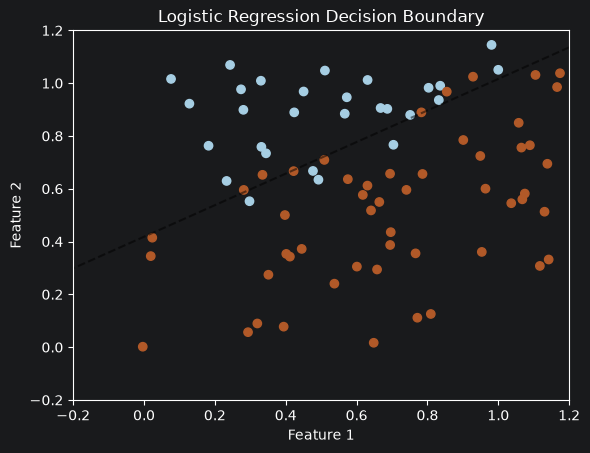

In [80]:
 #Plot the 80 training samples.
# X[0, :80] = Feature 1 values, X[1, :80] = Feature 2 values.
# The label Y[:80] determines each point's color
plt.scatter(X[0, :80], X[1,:80], c=Y[:80], cmap=plt.cm.Paired) #creates a scatter plot of the data values
plt.xlim(-0.2, 1.2) #boundaries of graph
plt.ylim(-0.2, 1.2) # boundaries of graph

# Get the current graph axes so we can use its x- and y-axis limits.
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

#Create a 50 by 50 grid of possible Feature 1 and Feature 2 locations.
xx, yy = np.meshgrid(np.linspace(xlim[0], xlim[1], 50), np.linspace(ylim[0], ylim[1], 50))

# Calculate the model's linear score, w1*x1 + w2*x2 + b,
# at every point in the grid.
Z = np.dot(w.T, np.c_[xx.ravel(), yy.ravel()].T) + b

# Convert each score into a probability between 0 and 1.
Z = sigmoid(Z)

# Change the one-dimensional list of probabilities into the same
# 50 by 50 shape as xx and yy so it can be plotted as a contour.
Z = Z.reshape(xx.shape)

#Draw the decision boundary where the predicted probability is 0.5.
# This is the border between the model predicting class 0 and class 1.
plt.contour(xx, yy, Z, colors='k', levels=[0.5], alpha=0.5, linestyles=['--'])

# Add labels and a title, then display the graph.
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Logistic Regression Decision Boundary')
plt.show()

This graph displays the 20 test samples in the $(x_1,x_2)$ feature
space, with color representing each true test label $y \in \{0,1\}$.

The dashed contour is the learned decision boundary
$\sigma(w_1x_1+w_2x_2+b)=0.5$, or equivalently
$w_1x_1+w_2x_2+b=0$, used to classify the unseen test data.

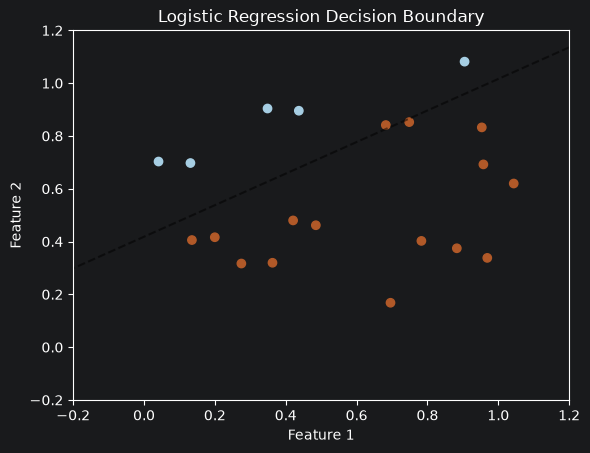

In [81]:
# Plot the 20 test samples.
# X[0, 80:] contains Feature 1; X[1, 80:] contains Feature 2.
# The true test label in Y[80:] determines each point's color.
plt.scatter(X[0, 80:], X[1, 80:], c=Y[80:], cmap=plt.cm.Paired)
#Set the visible boundaries of the graph.
plt.xlim(-0.2, 1.2)
plt.ylim(-0.2, 1.2)

# Get the current graph axes and their limits.
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

#Make a 50 by 50 grid of locations covering the graph.
xx, yy = np.meshgrid(np.linspace(xlim[0], xlim[1], 50), np.linspace(ylim[0], ylim[1], 50))

# Calculate the learned model's score, w1*x1 + w2*x2 + b,
# at every location on the grid.

Z = np.dot(w.T, np.c_[xx.ravel(), yy.ravel()].T) + b
# Convert the scores to predicted probabilities from 0 to 1.
Z = sigmoid(Z)
# Reshape the probabilities into a 50 by 50 grid for contour plotting.
Z = Z.reshape(xx.shape)
# Draw the dashed decision boundary where predicted probability = 0.5.
plt.contour(xx, yy, Z, colors='k', levels=[0.5], alpha=0.5, linestyles=['--'])

# Add axis labels and a title, then show the test-data graph.
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Logistic Regression Decision Boundary')
plt.show()

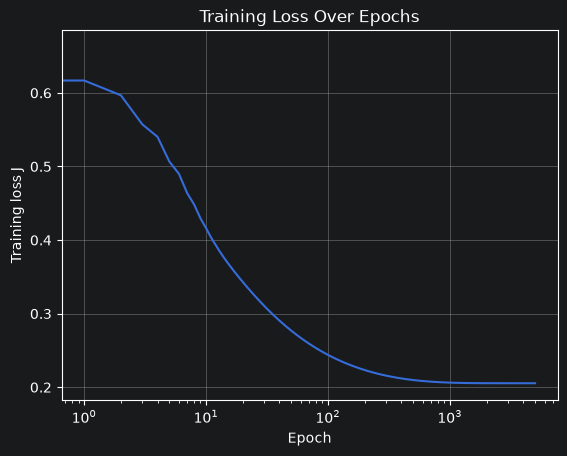

In [82]:
# 4.2 Plot the training loss J vs. epoch for your chosen learning_rate and num_epochs.

#one integer for every epoch in num epochs
k = np.arange(len(J_history))

#plot of J vs epochs
plt.plot(k, J_history)
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training loss J")
plt.title("Training Loss Over Epochs")
plt.grid(True)
plt.show()

### 4.1 Discussion (write your answer here)

*How did you choose `learning_rate` and `num_epochs`? How do you know $\boldsymbol\theta$ is close to $\boldsymbol\theta^\ast$?*

I started with testing different values of the learning rate. First, I tested 10 and saw that the J values oscillated wildly, then I tested 2 and saw the values decrease very slowly with each iteration of J. I ended up with the value of 4.9, which was not  too slow and did not overshoot. But J changed value more than 10^-6 with 595 epochs. I tried 10000 and J converged, I then tested to see what was the smallest value of epochs were J converged; I ended up 5,000

---
## Q5. Image Binary Classification (30 pts)

**Complete this question in two separate notebooks** (see Project Requirements): `LastName_FirstName_HW3_Q5a.ipynb` for Tasks 5.1 and 5.2, and `LastName_FirstName_HW3_Q5b.ipynb` for Task 5.3. Copy the relevant task descriptions into each notebook as markdown.

**Datasets** (posted on Brightspace with this notebook):
* training set: `train_catvnoncat.h5` (209 images; keys `train_set_x`, `train_set_y`, `list_classes`)
* test set: `test_catvnoncat.h5` (50 images; keys `test_set_x`, `test_set_y`, `list_classes`)

**Place both `.h5` files in the same folder as your Q5 notebooks.** The loading code opens the files by name only, so it will fail with `FileNotFoundError` if they are stored elsewhere. Do not hard-code a full path from your own computer, since the grader must be able to run your notebook unchanged.

Each image is a $64 \times 64$ RGB image, and each label is $1$ (cat) or $0$ (non-cat). Read the files with `h5py`. Flatten each image into a vector of $64 \cdot 64 \cdot 3 = 12288$ pixel values and scale the pixel values to $[0, 1]$ by dividing by 255.

All indices you report must be **0-based**, following Python convention.

### Tasks

**5.1 Re-implement the classifier (10 pts)** *(notebook Q5a).* Re-implement, from scratch, the logistic regression image classifier covered in class: parameter initialization, forward pass (sigmoid), cost, gradients, the gradient descent update loop, and a prediction function. You may consult the class code on Brightspace if you get stuck, but write the code yourself. Print the learning rate and number of iterations you used, plot the cost versus iteration, and print the training and test accuracies (in %, 2 decimals).

**5.2 Failure analysis (8 pts)** *(notebook Q5a).*
* (4 pts) Print the indices of **all** images in the test set that the model misclassifies, and the total count.
* (4 pts) Display at least 4 of these misclassified images in a grid. Title each image with its index, true label, and predicted label (for example, `idx 5: true=cat, pred=non-cat`).

**5.3 Modified train/test split (12 pts)** *(notebook Q5b).* Discard the original test set. Using only the 209 images in `train_catvnoncat.h5`, let $d$ be the last digit of your SBU ID and define:
* new training set: the first $160 + d$ images (indices $0$ to $159 + d$);
* new test set: the remaining $49 - d$ images (indices $160 + d$ to $208$).

For example, if $d = 0$, the training set has 160 images and the test set has 49 images; if $d = 9$, they have 169 and 40 images. Print the sizes of both new sets.
* (6 pts) Retrain the model from scratch on the new training set (same preprocessing; state your hyperparameters) and print the training and test accuracies (in %, 2 decimals).
* (6 pts) Print the indices of all misclassified images in the new test set. For each, give **both** its position within the new test set and its original index in `train_catvnoncat.h5`. Display at least 4 of them as in Task 5.2.

In a short markdown cell at the end of Q5b, compare the test accuracy from 5.3 with the one from 5.1 and give one possible reason for the difference.

In [83]:
# Q5 is completed in the two separate notebooks LastName_FirstName_HW3_Q5a.ipynb and
# LastName_FirstName_HW3_Q5b.ipynb. A suggested way to load the data:
#
# import h5py
# with h5py.File('train_catvnoncat.h5', 'r') as f:
#     train_x_orig = np.array(f['train_set_x'])   # shape (209, 64, 64, 3)
#     train_y = np.array(f['train_set_y'])        # shape (209,)
#     classes = np.array(f['list_classes'])       # [b'non-cat', b'cat']

---
## Grading Rubric

This project is worth **150 points** in total.

**Q1. Presentation, documentation, and submission: 10 points**
* 3 pts: clear, meaningful code comments.
* 3 pts: every figure has a title, axis labels, and a legend where needed.
* 2 pts: logical cell structure with markdown explanations; math written in LaTeX.
* 2 pts: correct file names; all cells executed with outputs visible; ZIP and merged PDF submitted.

**Q2. Gradient descent: 60 points**
* 10 pts: correct $f'(x)$, $x^\ast$, $f(x^\ast)$ (5); correct $f''(x)$, $L$, and $2/L$ (5).
* 5 pts: plot of $f$ on $[-5, 5]$ with $x^\ast$ marked.
* 15 pts: `gradient_descent` correctly implements the update with the analytic derivative and returns $[x_0, \dots, x_T]$.
* 5 pts: correct $x_0$ from your ID; $x_T$ and $f(x_T)$ reported for $\alpha = 1$, $T = 50$.
* 10 pts: plot of $f(x_k)$ vs. $k$ with the reference line at $f(x^\ast)$.
* 15 pts: single figure of $\Delta_k$ vs. $k$ for all four step sizes (10); correct discussion of monotonicity tied to $2/L$, supported by printed $\min_k \Delta_k$ (5).

**Q3. Linear regression: 30 points**
* 5 pts: correct seed and design matrix $X_b$ of shape $(100, 3)$.
* 10 pts: $\hat{\boldsymbol\theta}$ computed correctly with the normal equation, without library regression routines.
* 5 pts: parameters reported next to the true values, MSE reported, and the deviation explained.
* 10 pts: 3D scatter of the data with the fitted plane, axes labeled.

**Q4. Logistic regression: 20 points**
* 8 pts: tuned `learning_rate` and `num_epochs` meet the convergence criterion; final $\mathbf{w}$, $b$, $J$, and accuracies printed; choice justified.
* 4 pts: training loss curve.
* 8 pts: accurate, informative comments on all three code cells.

**Q5. Image binary classification: 30 points**
* 10 pts: from-scratch classifier with cost curve and train/test accuracies (Q5a).
* 8 pts: all misclassified test indices (4) and at least 4 labeled images (4) (Q5a).
* 12 pts: correct ID-based split and retrained accuracies (6); misclassified indices in both index systems with at least 4 labeled images (6) (Q5b).

Submissions are evaluated on correctness, clarity, completeness, originality, and adherence to the project guidelines.